# Modeling Above Ground Biomass with Spatially Aware Machine Learning

Adaptation of the original AGB project (ESA CCI Biomass + Sentinel-1/2 + SRTM + canopy height, Mangueirinha Indigenous Land) using spatially explicit concepts: ESDA, spatial dependence, spatial cross-validation and spatial feature selection.

**Environment:** `mamba env create -f environment.yml` and `mamba activate biomass-spatial-modeling` (see README).

| # | Section | Spatial concept |
|---|---|---|
| 0 | Environment and configuration | reproducibility, projected CRS |
| 1 | Area of interest | |
| 2 | Data collection | sampling grid, extraction in metric CRS |
| 3 | Exploratory data analysis | collinearity |
| 4 | ESDA | Moran's I, LISA, semivariogram (range) |
| 5 | Spatial split | range-informed blocks, spatial folds, independent test |
| 6 | Spatial feature selection | MDI/MDA inside spatial CV |
| 7 | Models | RF, XGB, MLP tuned with spatial CV; random-CV baseline |
| 8 | Spatial model | RF + spatial lag |
| 9 | Accuracy assessment | CV vs. test, residual Moran's I |
| 10 | Explanation | SHAP |
| 11 | Final map | prediction, difference to ESA, uncertainty |

# 0. Environment and configuration

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
import seaborn as sns
from shapely.geometry import box

import ee
import geemap

from libpysal.weights import KNN
from libpysal.weights.spatial_lag import lag_spatial
from esda.moran import Moran, Moran_Local
from skgstat import Variogram

from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold, GroupKFold, cross_val_predict
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import xgboost as xgb
import shap
from bayes_opt import BayesianOptimization

In [2]:
SEED = 42
DATA_DIR = Path("../input")
OUTPUT_DIR = Path("../output")
OUTPUT_DIR.mkdir(exist_ok=True)

CRS_GEO = "EPSG:4326"
CRS_PROJ = "EPSG:31982"  # SIRGAS 2000 / UTM 22S, used for distances and blocks
EE_PROJECT = "ee-sandrosenamachado"
YEAR = 2020

In [3]:
# Authenticate and initialize the Earth Engine API
ee.Authenticate() 
ee.Initialize(project=EE_PROJECT)

# 1. Area of Interest (AOI)
Mangueirinha Indigenous Land (western Paraná, Iguaçu basin). Field inventory reference: 151 t/ha (NFI).

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

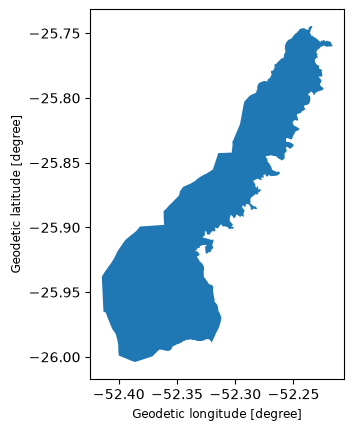

In [4]:
# Load the indigenous lands shapefile
gdf = gpd.read_file(f'{DATA_DIR}/dashboard_indigenous-lands-static-layer.shp')

# Select relevant columns
gdf = gdf[['id', 'name', 'area_ha', 'geometry']]

# Filter the AOI by name 'Mangueirinha'
aoi_shp = gdf[gdf['name'] == 'Mangueirinha']

# Check the shape
aoi_shp.plot()

In [5]:
# Transform shapefile to JSON
shp_json = aoi_shp.to_json()

# Load JSON file
aoi = json.loads(shp_json)

# Select features
aoi = aoi['features']

In [6]:
# Create a feature collection with the JSON
region = ee.FeatureCollection(aoi)

In [7]:
# Add feature to de map and draw its contours

# Instaciate geepmap display function (Map)
Map = geemap.Map()

# Draw AOI contour
image_region = ee.Image().paint(region, 0, 2)

# Add layer
Map.addLayer(image_region,{'palette':'red'}, 'AOI')

# Centralize AOI
Map.centerObject(region,10)

# Set basemap
Map.set_options('')

# Call Map funciton
Map

Map(center=[-25.89337715679996, -52.325960071094], controls=(WidgetControl(options=['position', 'transparent_b…

# 2. Data collection

The preprocessing, indices, dates and sampling sequence below reproduce the original
AGB notebook for Mangueirinha (ESA CCI 2020). The original formulas are retained,
including expressions that should be reviewed separately before interpreting them.
To support spatial analysis, longitude and latitude are added to the final samples;
the export uses a Drive batch task rather than transferring the full table with `getInfo()`.

ESA CCI is a modelled product, not independent field observations. The original
model-fitting section also loaded an external dataset; equivalence to that dataset
must be checked before interpreting differences in model performance.

## 2.1 Target: ESA CCI AGB

In [8]:
# Access ESA CCI Above Ground Biomass (AGB) dataset
esa_agb = ee.ImageCollection('projects/sat-io/open-datasets/ESA/ESA_CCI_AGB')

# Filter by date and select the first image for 2020
esa_agb = esa_agb.filterDate('2020-01-01', '2020-12-31').first().select(['AGB'])

# Color palette for visualization
vis_palette = ["#C6ECAE","#A1D490","#7CB970","#57A751","#348E32", "#267A29","#176520","#0C4E15","#07320D","#031807"]

# Visualizing
Map.addLayer(esa_agb,{'palette':vis_palette,'min':1,'max':450},'Above Ground Biomass 2020')
Map.addLayer(esa_agb.clip(region),{'palette':vis_palette,'min':1,'max':450},'Above Ground Biomass 2020 (Cliped)')
Map.centerObject(region,11)
Map

Map(center=[-25.893377156799872, -52.325960071094045], controls=(WidgetControl(options=['position', 'transpare…

In [9]:
# Clip the dataset for the area of interest
esa_agb = esa_agb.clip(region)

# Calculate the mean AGB (t/ha) at the AOI using zonal statistics
mean_biomass = esa_agb.reduceRegion(**{
    'reducer': ee.Reducer.mean(),
    'geometry': region,
    'scale': 100,  # Proper scale for the dataset
    'maxPixels': 1e9
})

# Get mean AGB value for the AOI
mean_biomass_value = mean_biomass.get('AGB').getInfo()

# Print the mean value
print(f'Mean Biomass (t/ha) in study area: {mean_biomass_value}')

# Compare with the National Forest Inventory AGB value
biomass_inventory = 151

# Print comparison
difference = mean_biomass_value - biomass_inventory
print(f'Difference between GEE and inventory biomass (t/ha): {difference}')


Mean Biomass (t/ha) in study area: 165.6085437549147
Difference between GEE and inventory biomass (t/ha): 14.608543754914706


## 2.2 Predictors

### ETH Global Sentinel-2 10m Canopy Height (2020)

In [11]:
# ******** Load canopy top height (Lang et al., 2021) ********
# Define a color palette ("inferno") for canopy heights ranging from 0 m to 50 m
canopy_vis = {
    "min": 0.0,
    "max": 50.0,
    "palette": ['#010005', '#150b37', '#3b0964', '#61136e', '#85216b', '#a92e5e', '#cc4248', '#e75e2e', '#f78410', '#fcae12', '#f5db4c', '#fcffa4'],
}
# Define a color palette ("mako") for standard deviation ranging from 0 m to 15 m
sd_vis = {
    "min": 0.0,
    "max": 15.0,
    "palette": ['#0d0406', '#241628', '#36274d', '#403a76', '#3d5296', '#366da0', '#3488a6', '#36a2ab', '#44bcad', '#6dd3ad', '#aee3c0', '#def5e5'],
}
# Optional add UMD Canopy height map
#umd_canopy_height = ee.ImageCollection('users/potapovpeter/GEDI_V27')
#Map.addLayer(umd_canopy_height, canopy_vis, 'UMD Global Forest Canopy Height 2019')
standard_deviation = ee.Image('users/nlang/ETH_GlobalCanopyHeightSD_2020_10m_v1')
Map.addLayer(standard_deviation, sd_vis, 'Standard deviation')
canopy_height = ee.Image('users/nlang/ETH_GlobalCanopyHeight_2020_10m_v1')
Map.addLayer(canopy_height.clip(region), canopy_vis, 'Canopy top height')
Map.centerObject(region,11)
Map

Map(center=[-25.893377156799872, -52.325960071094045], controls=(WidgetControl(options=['position', 'transpare…

### Harmonized Sentinel-2 MSI: Multispectral Instrument, Level 2A

In [12]:
# Mascara de nuvens para a banda pixel_qa SR Sentinel 2
def maskS2clouds(image):
  qa = image.select('QA60')
  # Bits 10 and 11 are clouds and cirrus, respectively.
  cloudBitMask = 1 << 10
  cirrusBitMask = 1 << 11
  # Both flags should be set to zero, indicating clear conditions.
  mask = qa.bitwiseAnd(cloudBitMask).eq(0).And(qa.bitwiseAnd(cirrusBitMask).eq(0))
  #Return the masked and scaled data, without the QA bands.
  return image.updateMask(mask).divide(10000)\
      .select("B.*")\
      .copyProperties(image, image.propertyNames())\
      .set('data', image.date().format('YYYY-MM-dd'))\
      .set({'millis': image.date().millis()})\
      .set({'ID': image.get('system:index')})

def calculate_indices(image):
    # Selecionar as bandas necessárias
    blue = image.select('B2')  # Banda Azul
    green = image.select('B3')  # Banda Verde
    red = image.select('B4')  # Banda Vermelha
    nir = image.select('B8')  # Banda NIR (Infravermelho Próximo)
    swir1 = image.select('B11')  # Banda SWIR1 (Infravermelho de Onda Curta 1)
    swir2 = image.select('B12')  # Banda SWIR2 (Infravermelho de Onda Curta 2)
    NIRnarrow = image.select('B8A') # Infravermelho próximo
    rededge1 = image.select('B5') # Borda do vermelho 1
    rededge2 = image.select('B6')
    rededge3 = image.select('B7')


    # Calculando os índices
    evi = image.expression(
        '2.5 * (NIR - RED) / (NIR + 6 * RED - 7.5 * BLUE + 1)', {
            'NIR': nir,
            'RED': red,
            'BLUE': blue
        }).rename('EVI') # Enhanced Vegetation Index

    savi = image.expression(
            "((NIRnarrow - RED) / (NIRnarrow + RED + 0.5) * 1.5)",
            {
              'NIRnarrow': NIRnarrow,
              'RED': red
    }).rename('SAVI') # Soil Adjusted Vegetation Index

    SRBlueRededge1 = image.expression(
                    "(BLUE / REDedge1)",
                    {
                      'BLUE': blue,
                      'REDedge1': rededge1
                }).rename('SRBlueRededge1') # SR-BlueRededge1 (Simple Blue and Red-edge 1 Ratio)


    SRNIRnarrowRededge1 = image.expression(
                          "(NIRnarrow / REDedge1)",
                          {
                            'NIRnarrow': NIRnarrow,
                            'REDedge1': rededge1
                  }).rename('SRNIRnarrowRededge1') # SR-NIRnarrowRededge1 (Simple NIR and Red-edge 1 Ratio)

    SRNIRnarrowRededge2 = image.expression(
                          "(NIRnarrow / REDedge2)",
                          {
                            'NIRnarrow': NIRnarrow,
                            'REDedge2': rededge2
                  }).rename('SRNIRnarrowRededge2') # SR-NIRnarrowRededge2 (Simple NIR and Red-edge 2 Ratio)


    PSSRa = image.expression(
              "(NIR / RED)",
              { 'NIR': nir,
                'RED': rededge1
      }).rename('PSSRa') # Pigment Specific Simple Ratio (chlorophyll index)


    GCI = image.expression(
              "((NIR/Green))-1",
              {
                'NIR': nir,
                'Green': green,
      }).rename('GCI') # Green Chlorophyll Index


    Lcaroc = image.expression(
        "(Rededge3) / (Blue - Rededge1)",
        { 'Rededge3': rededge3,
          'Blue': blue,
          'Rededge1': rededge1,
          }).rename('Lcaroc') # (Leaf Carotenoid Content)


    Lchloc = image.expression(
        "(Rededge3) / (Rededge1)",
        { 'Rededge3': rededge3,
          'Rededge1': rededge1,
          }).rename('Lchloc')


    LAI = image.expression('LAI = (0.3977 * exp(2.5556 * (NIR - RED) / (NIR + RED)))',
                          {
                              'NIR': nir,
                              'RED': red
                          }).rename('LAI') # Leaf Area Index (Leaf Area Index)

    PSRI = image.expression(
        "(Red-Green)/Rededge2",
        { 'Red': red,
          'Green': green,
         'Rededge2': rededge2,
          }).rename('PSRI') # (Plant Senescence Reflectance Index)

    nbr = image.normalizedDifference(['B8', 'B12']).rename('NBR')
    ndmi = image.normalizedDifference(['B8', 'B11']).rename('NDMI')
    ndwi = image.normalizedDifference(['B3', 'B8']).rename('NDWI')
    mndwi = image.normalizedDifference(['B3', 'B11']).rename('MNDWI')
    ndvi = image.normalizedDifference(['B8', 'B4']).rename('NDVI')
    gNDVI = image.normalizedDifference(['B8', 'B3']).rename('gNDVI') #(Green Normalized Difference Vegetation Index)
    NDVIre = image.normalizedDifference(['B8', 'B5']).rename('NDVIre') #(Normalized Difference Vegetation Index Red-edge)


    return image.addBands([evi,nbr,ndmi,ndwi,mndwi,ndvi,savi,gNDVI,NDVIre,SRBlueRededge1,
                           SRNIRnarrowRededge1,SRNIRnarrowRededge2,PSSRa,GCI,Lcaroc,Lchloc,PSRI,LAI])

##Agora vamos obter um ee.Image de um ee.ImageCollection
Sentinel2 = ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")\
         .filterBounds(ee.Geometry.Point([-52.34007901938789,-25.901559629835102]))\
         .filterDate('2020-01-01', '2020-12-31')\
         .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE',5))\
         .map(maskS2clouds)\
         .select(['B.*'])\
         .map(calculate_indices)


print('Nº total de imagens :', Sentinel2.size().getInfo())

# Original composite, without the optional map display.
imageS2 = Sentinel2.median().clip(region)

Nº total de imagens : 27


### NASA SRTM Digital Elevation 30m (Shuttle Radar Topography Mission)

In [13]:
# .log(): Esta função aplica uma transformação logarítmica aos valores de elevação da imagem.
# Essa transformação é frequentemente usada para reduzir a variação nos dados de elevação,
# tornando os padrões mais fáceis de identificar, especialmente quando há grandes diferenças nos valores de elevação.

# .divide(10): A imagem resultante da transformação logarítmica é então dividida por 10.
# Esta é uma forma de normalização e pode ser específica para o contexto ou objetivo da análise.

# Adicionando dados de Elevação
srtm = ee.Image("USGS/SRTMGL1_003")
srtm = srtm.clip(region).log().divide(10).toFloat()

# Reprojete a image e adicione a banda do DEM...
image_s2_srtm = imageS2.addBands([srtm])
                    # .reproject('EPSG:4326', None, 100)

image_s2_srtm.bandNames().getInfo()

['B1',
 'B2',
 'B3',
 'B4',
 'B5',
 'B6',
 'B7',
 'B8',
 'B8A',
 'B9',
 'B11',
 'B12',
 'EVI',
 'NBR',
 'NDMI',
 'NDWI',
 'MNDWI',
 'NDVI',
 'SAVI',
 'gNDVI',
 'NDVIre',
 'SRBlueRededge1',
 'SRNIRnarrowRededge1',
 'SRNIRnarrowRededge2',
 'PSSRa',
 'GCI',
 'Lcaroc',
 'Lchloc',
 'PSRI',
 'LAI',
 'elevation']

### Sentinel-1 SAR GRD: C-band Synthetic Aperture Radar Ground Range Detected, log scaling

In [14]:
# Referência: Erli Pinto dos Santos <https://github.com/eupassarinho/GoogleEarthEngine-sentinel1-vegetation-indices>

# SENTINEL-1 DATA PROCESSING: #
# The goal of this algorithm is process SAR images from Sentinel-1. The code does:

# 1) Creates a function to apply a speckle filter: in this case by Focal Median method

# 2) Creates a function that will, based on band histogram (from VV and VH FLOAT bands),
# remove a "heavy-tail" from their histograms: this part of distribution that is understood as
# outliers

# 3) Applying all functions above, the code creates a variable containing an image
# collection for each band. The result are the bands Sigma0_VV and Sigma0_VH

# 5) Creates and applies functions to compute all the SAR vegetation indices of interest:
# DPSVI original (Periasamy, 2018) and DPSVI modified


# Function to apply speckle noise removal filter by Focal Median:
# The window (the kernel) used to apply the filter is in pixel number, that is odd number
def MedianVV(image):
    return image.addBands(image.focal_median(**{'radius': 5,
                                                'kernelType': 'square',
                                                'units': 'pixels'})
                          .rename(['Sigma0_VV']))

def MedianVH(image):
    return image.addBands(image.focal_median(**{'radius': 5,
                                                'kernelType': 'square',
                                                'units': 'pixels'})
                          .rename(['Sigma0_VH']))

# Function to mask outliers in VV band based on histogram analysis
def maskVV(image):
    quantil90 = image.reduceRegion(**{'reducer':
                                      ee.Reducer.percentile(**{'percentiles': ee.List([95]),
                                                               'outputNames': ee.List(['p95'])}),
                                      'scale': 10,
                                      'bestEffort': True})
    Outliers = image.select('VV').lte(ee.Number(quantil90.get('VV')))
    return image.updateMask(Outliers)

def maskVH(image):
    quantil90 = image.reduceRegion(**{'reducer':
                                      ee.Reducer.percentile(**{'percentiles': ee.List([95]),
                                                               'outputNames': ee.List(['p95'])}),
                                      'scale': 10,
                                      'bestEffort': True})
    Outliers = image.select('VH').lte(ee.Number(quantil90.get('VH')))
    return image.updateMask(Outliers)

# Vars that will receive and pre-process the Sentinel-1 SAR choiced images:

sentinel1VV =   ee.ImageCollection('COPERNICUS/S1_GRD_FLOAT') \
                  .filter(ee.Filter.eq('instrumentMode', 'IW')) \
                  .filter(ee.Filter.eq('orbitProperties_pass', 'DESCENDING')) \
                  .filter(ee.Filter.eq('relativeOrbitNumber_start', 97)).filter(ee.Filter.eq('resolution_meters', 10)) \
                  .filterBounds(region).filter(ee.Filter.eq('resolution_meters', 10)) \
                  .filterBounds(region).filterDate('2020-01-01', '2020-12-31') \
                  .select('VV') \
                  .map(maskVV) \
                  .map(MedianVV) \
                  .select('Sigma0_VV')

# VH band
sentinel1VH =   ee.ImageCollection('COPERNICUS/S1_GRD_FLOAT').filter(ee.Filter.eq('instrumentMode', 'IW')) \
                .filter(ee.Filter.eq('orbitProperties_pass', 'DESCENDING')) \
                .filter(ee.Filter.eq('relativeOrbitNumber_start', 97)).filter(ee.Filter.eq('resolution_meters', 10)) \
                .filterBounds(region).filterDate('2020-01-01', '2020-12-31')\
                .select('VH') \
                .map(maskVH) \
                .map(MedianVH) \
                .select('Sigma0_VH')

# Combining both image collections (Sigma0_VV and Sigma0_VH):
sentinel1 = sentinel1VV.combine(sentinel1VH)
#print(sentinel1, "Sentinel-1 filtered images")

# Computing vegetation index over each image in collection:
# The outputs of this function are:
# The original Dual Polarization SAR Vegetation Index (DPSVI; Periasamy, 2018)
# and the modified DPSVI (proposed here):
def indices(image):
    max = image.reduceRegion(**{
        'reducer': ee.Reducer.max(),
        'scale': 10,
        'geometry': region,
        'bestEffort': True
    })
    DPSVIoriginal = image.expression(
        '(((VVmax - VV)+VH)/1.414213562) * ((VV+VH)/VV) * VH', {
            'VH': image.select('Sigma0_VH'),
            'VV': image.select('Sigma0_VV'),
            'VVmax': ee.Number(max.get('Sigma0_VV'))
        }
    )
    DPSVIm = image.expression(
        '(VV*VV+VV*VH)/1.414213562', {
            'VH': image.select('Sigma0_VH'),
            'VV': image.select('Sigma0_VV')
        }
    )

    SARVI = image.expression(
        '(VH/ VV + VH)', {
            'VH': image.select('Sigma0_VH'),
            'VV': image.select('Sigma0_VV')}
    )

    razaoVVVH = image.expression(
        '(VV/VH)', {
            'VH': image.select('Sigma0_VH'),
            'VV': image.select('Sigma0_VV')}
    )

    NDSI = image.expression(
        '(VV-VH/VV+VH)',{
        'VH': image.select('Sigma0_VH'),
        'VV': image.select('Sigma0_VV')}
    )

    return image.addBands([
        DPSVIm.rename("DPSVIm"),
        DPSVIoriginal.rename("DPSVIo"),
        SARVI.rename("SARVI"), # SAR Vegetation Index
        razaoVVVH.rename("razaoVVVH"), # Razão VV / VH
        NDSI.rename("NDSI") # Normalized Difference Backscattering
    ])

S1_indices = sentinel1.map(indices)
imageS1 = S1_indices.median().clip(region)
imageS1_reprojetada = imageS1.reproject('EPSG:4326', None, 100)

## 2.3 Sampling and extraction

As in the original: sample ESA at 350 m, then extract ESA, canopy height and
Sentinel-1 successively at 100 m; finally sample the combined Sentinel-2, SRTM,
Sentinel-1 and canopy image at 100 m. Earth Engine evaluates this chain lazily:
the intermediate collections are not independently persisted.

The only additions are the coordinates attached after the final extraction and
the Drive export. `tileScale=4` reduces aggregation tile size without changing
the requested sample scale; it does not guarantee that the export fits in memory.

In [15]:
# Original sampling sequence (cells 46, 48, 58, 86, 89-90 and 96).
grid_samples = esa_agb.sample(region=region, geometries=True, scale=350)
extract_agb = esa_agb.sampleRegions(
    collection=grid_samples, scale=100, geometries=True, tileScale=4
)
extract_canopy = canopy_height.sampleRegions(
    collection=extract_agb, scale=100, geometries=True, tileScale=4
)
extract_sentinel1 = imageS1_reprojetada.sampleRegions(
    collection=extract_canopy, scale=100, geometries=True, tileScale=4
)
imageS2_S1 = image_s2_srtm.addBands(imageS1_reprojetada)
image_s2_s1_b1 = imageS2_S1.addBands(canopy_height)
samples_original = image_s2_s1_b1.sampleRegions(
    collection=extract_sentinel1, scale=100, geometries=True, tileScale=4
)

def add_coordinates(feature):
    coordinates = feature.geometry().transform(CRS_GEO, 1).coordinates()
    return feature.set("longitude", coordinates.get(0), "latitude", coordinates.get(1))

ee_samples = samples_original.map(add_coordinates)
print("Original sampling chain prepared; extraction runs when the export is submitted.")

Original sampling chain prepared; extraction runs when the export is submitted.


In [21]:
# Original output fields plus coordinates for spatial analysis.
labels = ['AGB', 'b1', 'EVI', 'MNDWI', 'NBR', 'NDMI', 'NDVI', 'NDWI', 'SAVI', 'elevation', 'gNDVI', 'NDVIre', 'SRBlueRededge1', 'SRNIRnarrowRededge1', 'SRNIRnarrowRededge2', 'PSSRa', 'GCI', 'Lcaroc', 'Lchloc', 'PSRI', 'LAI', 'Sigma0_VV', 'Sigma0_VH', 'DPSVIm', 'DPSVIo', 'SARVI', 'razaoVVVH', 'NDSI']

# Set to True and run once to submit the asynchronous Drive task.
RUN_EXPORT = True
if RUN_EXPORT:
    export_task = ee.batch.Export.table.toDrive(
        collection=ee_samples,
        description=f"biomass_samples_{YEAR}",
        folder="biomass-spatial-modeling",
        fileNamePrefix=f"samples_agb_{YEAR}",
        fileFormat="CSV",
        selectors=labels + ["longitude", "latitude"],
    )
    export_task.start()
    print(export_task.status())
else:
    print("Export not started. Set RUN_EXPORT = True to submit the task.")

{'state': 'READY', 'description': 'biomass_samples_2020', 'priority': 100, 'creation_timestamp_ms': 1795118432318, 'update_timestamp_ms': 1795118432318, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_FEATURES', 'id': 'EWHXXDENPN3T7IJP5ADESYYA', 'name': 'projects/ee-sandrosenamachado/operations/EWHXXDENPN3T7IJP5ADESYYA'}


In [17]:
# After the task finishes, download samples_agb_2020.csv from the
# biomass-spatial-modeling Drive folder into DATA_DIR, then continue with section 3.

In [ ]:
export_task.status()

# 3. Exploratory data analysis
Non-spatial view of the response and predictors.

Rows read: 1515; invalid target/coordinates removed: 0
Samples: 1515 | CRS: EPSG:31982
AGB (t/ha): count    1515.000000
mean      165.887129
std        59.980632
min         2.000000
25%       133.000000
50%       188.000000
75%       212.000000
max       246.000000
Skewness: -1.006; excess kurtosis: -0.009


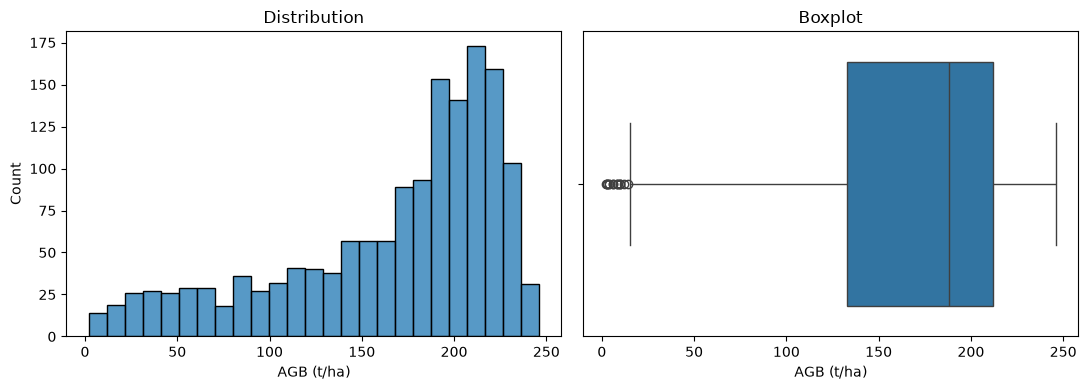

In [25]:
# Run this cell after downloading the export; it is also the offline entry point.
sample_path = DATA_DIR / f"samples_agb_{YEAR}.csv"
if not sample_path.exists():
    raise FileNotFoundError(
        f"Download the completed Earth Engine export to {sample_path.resolve()}"
    )
table = pd.read_csv(sample_path)
required = {"AGB", "longitude", "latitude"}
missing = required.difference(table.columns)
if missing:
    raise ValueError(f"Missing columns in sample file: {sorted(missing)}")
for column in required:
    table[column] = pd.to_numeric(table[column], errors="coerce")
valid = (table[list(required)].notna().all(axis=1)
         & np.isfinite(table[list(required)]).all(axis=1)
         & table["AGB"].ge(0)
         & table["longitude"].between(-180, 180)
         & table["latitude"].between(-90, 90))
print(f"Rows read: {len(table)}; invalid target/coordinates removed: {(~valid).sum()}")
table = table.loc[valid].copy()
if table.empty:
    raise ValueError("No valid samples remain after filtering.")
samples = gpd.GeoDataFrame(
    table,
    geometry=gpd.points_from_xy(table["longitude"], table["latitude"]),
    crs=CRS_GEO,
).to_crs(CRS_PROJ).reset_index(drop=True)
print("Samples:", len(samples), "| CRS:", samples.crs)
print("AGB (t/ha):", samples["AGB"].describe().to_string())
print(f"Skewness: {samples['AGB'].skew():.3f}; excess kurtosis: {samples['AGB'].kurt():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(samples["AGB"], bins=25, ax=axes[0])
sns.boxplot(x=samples["AGB"], ax=axes[1])
axes[0].set(xlabel="AGB (t/ha)", title="Distribution")
axes[1].set(xlabel="AGB (t/ha)", title="Boxplot")
plt.tight_layout()
plt.show()

Missing values by predictor:
b1                     0
EVI                    0
MNDWI                  0
NBR                    0
NDMI                   0
NDVI                   0
NDWI                   0
SAVI                   0
elevation              0
gNDVI                  0
NDVIre                 0
SRBlueRededge1         0
SRNIRnarrowRededge1    0
SRNIRnarrowRededge2    0
PSSRa                  0
GCI                    0
Lcaroc                 0
Lchloc                 0
PSRI                   0
LAI                    0
Sigma0_VV              0
Sigma0_VH              0
DPSVIm                 0
DPSVIo                 0
SARVI                  0
razaoVVVH              0
NDSI                   0


,count,mean,std,min,25%,50%,75%,max
b1,1515.0,19.328713,5.035036,2.000000,17.000000,20.000000,22.000000,32.000000
EVI,1515.0,0.504730,0.082797,0.128658,0.463298,0.513260,0.557845,0.781445
MNDWI,1515.0,-0.598877,0.031070,-0.690198,-0.620643,-0.600608,-0.580756,-0.450559
NBR,1515.0,0.595286,0.114796,-0.004905,0.592298,0.635775,0.658619,0.724105
NDMI,1515.0,0.303067,0.088853,-0.164706,0.296673,0.331049,0.354274,0.428302
NDVI,1515.0,0.828413,0.090332,0.288317,0.838255,0.860481,0.872526,0.924040
NDWI,1515.0,-0.757014,0.058912,-0.837419,-0.788287,-0.778659,-0.755403,-0.462495
SAVI,1515.0,0.493453,0.067029,0.182957,0.463475,0.502636,0.535329,0.694569
elevation,1515.0,0.666777,0.013443,0.622059,0.658824,0.669703,0.676041,0.694022
gNDVI,1515.0,0.757014,0.058912,0.462495,0.755403,0.778659,0.788287,0.837419


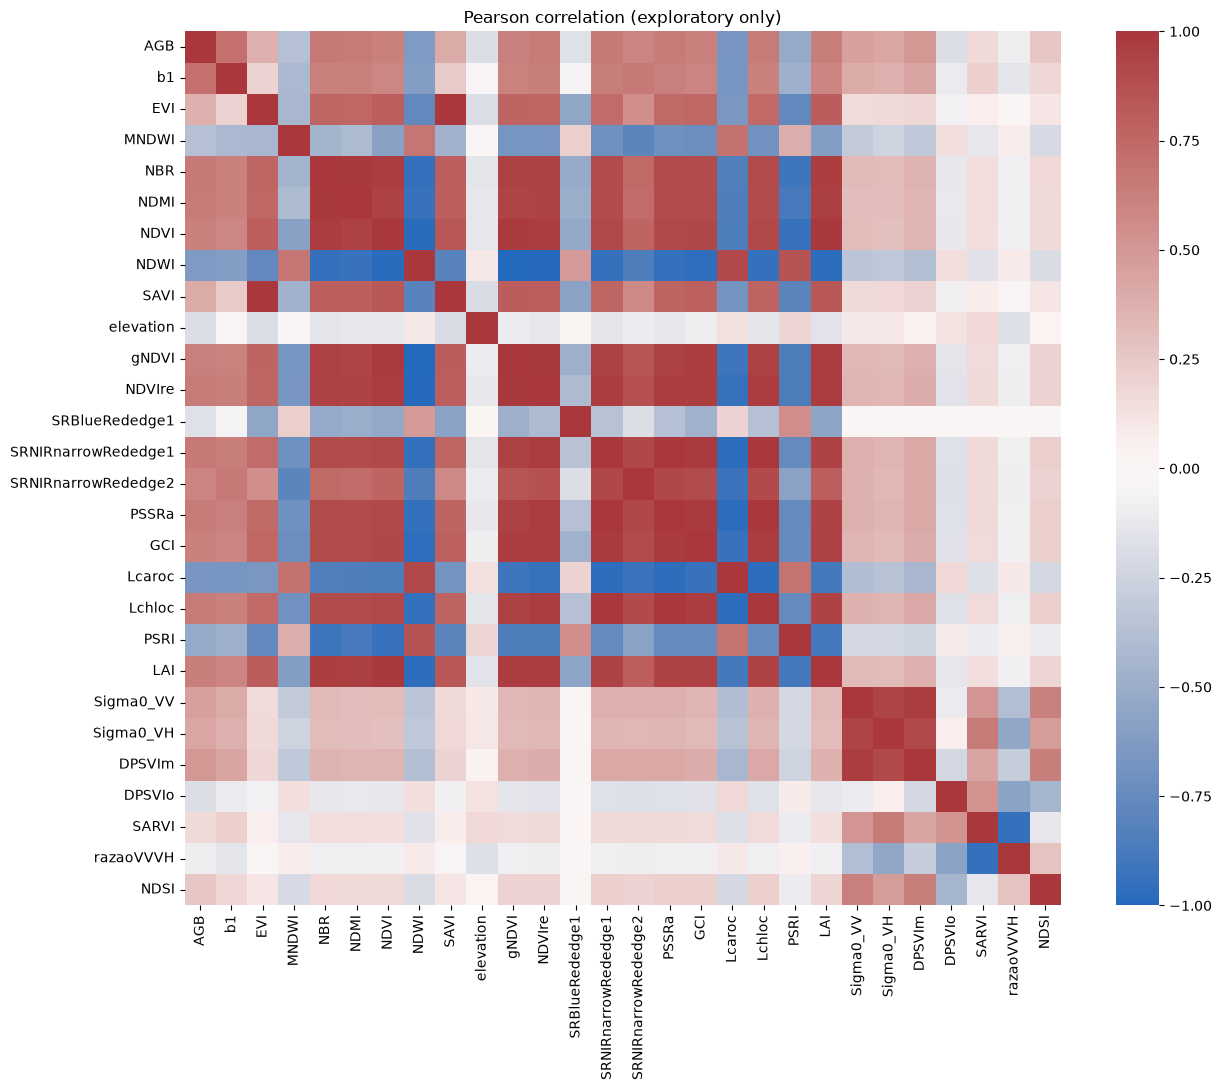

,level_0,level_1,correlation
171,NDWI,gNDVI,-1.000000
341,SRNIRnarrowRededge1,Lchloc,0.998317
338,SRNIRnarrowRededge1,PSSRa,0.997403
395,PSSRa,Lchloc,0.997048
34,EVI,SAVI,0.992437
...,...,...,...
152,NDVI,Lchloc,0.909638
589,Sigma0_VH,DPSVIm,0.906694
178,NDWI,Lcaroc,0.906330
259,gNDVI,Lcaroc,-0.906330


In [27]:
# Descriptive correlation only: feature filtering must be fitted within training folds.
predictor_columns = ['b1', 'EVI', 'MNDWI', 'NBR', 'NDMI', 'NDVI', 'NDWI', 'SAVI', 'elevation', 'gNDVI', 'NDVIre', 'SRBlueRededge1', 'SRNIRnarrowRededge1', 'SRNIRnarrowRededge2', 'PSSRa', 'GCI', 'Lcaroc', 'Lchloc', 'PSRI', 'LAI', 'Sigma0_VV', 'Sigma0_VH', 'DPSVIm', 'DPSVIo', 'SARVI', 'razaoVVVH', 'NDSI']
missing_predictors = set(predictor_columns).difference(samples.columns)
if missing_predictors:
    raise ValueError(f"Missing predictors in exported CSV: {sorted(missing_predictors)}")
samples[predictor_columns] = (samples[predictor_columns].apply(pd.to_numeric, errors="coerce")
                              .replace([np.inf, -np.inf], np.nan))
print("Missing values by predictor:")
print(samples[predictor_columns].isna().sum().sort_values(ascending=False).to_string())
display(samples[predictor_columns].describe().T)

corr = samples[["AGB"] + predictor_columns].corr()
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Pearson correlation (exploratory only)")
plt.tight_layout()
plt.show()

upper = corr.loc[predictor_columns, predictor_columns].where(
    np.triu(np.ones((len(predictor_columns), len(predictor_columns)), dtype=bool), k=1)
)
correlated_pairs = upper.stack().rename("correlation").reset_index()
correlated_pairs = correlated_pairs[correlated_pairs["correlation"].abs() >= 0.9]
display(correlated_pairs.sort_values("correlation", key=abs, ascending=False))

# 4. Exploratory spatial data analysis (ESDA)
Based on `cap423-slides/05/02_ESDA.ipynb`. Distances need a projected CRS.

## 4.1 Spatial distribution of AGB

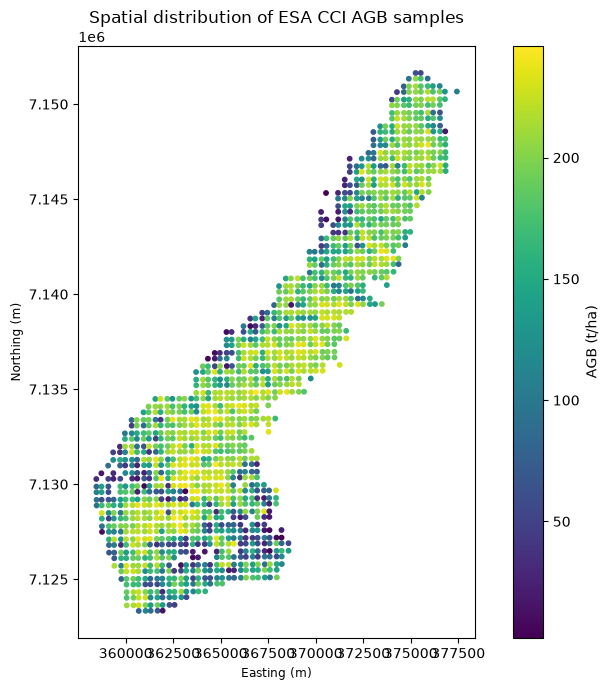

In [28]:
if samples.crs is None or samples.crs.is_geographic:
    raise ValueError("Reproject samples to a metric CRS before spatial analysis.")
if samples.geometry.is_empty.any() or samples.geometry.duplicated().any():
    raise ValueError("Empty or duplicate coordinates must be investigated before ESDA.")
if len(samples) <= 8 or samples["AGB"].nunique() < 2:
    raise ValueError("ESDA requires more than 8 samples and a non-constant AGB.")

fig, ax = plt.subplots(figsize=(8, 7))
samples.plot(column="AGB", cmap="viridis", markersize=10, legend=True, ax=ax,
             legend_kwds={"label": "AGB (t/ha)"})
ax.set_title("Spatial distribution of ESA CCI AGB samples")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
plt.tight_layout()
plt.show()

## 4.2 Global Moran's I and Moran scatterplot

Moran's I = 0.4811; expected = -0.0007; permutation p = 0.0010; connected components = 1


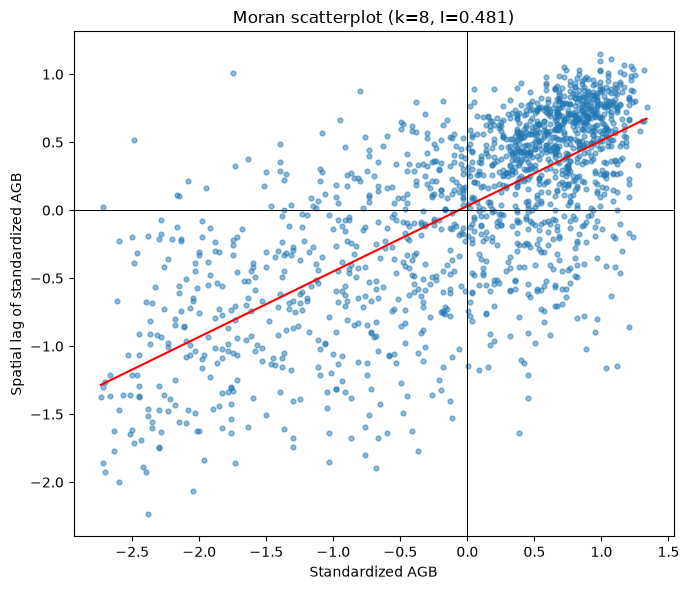

In [29]:
# KNN and permutations follow the class ESDA notebook.
k = 8
w = KNN.from_dataframe(samples, k=k)
w.transform = "R"
np.random.seed(SEED)
moran = Moran(samples["AGB"].to_numpy(), w, permutations=999)
print(f"Moran's I = {moran.I:.4f}; expected = {moran.EI:.4f}; "
      f"permutation p = {moran.p_sim:.4f}; connected components = {w.n_components}")

values = samples["AGB"].to_numpy()
z = (values - values.mean()) / values.std()
spatial_lag = lag_spatial(w, z)
slope, intercept = np.polyfit(z, spatial_lag, 1)
xline = np.linspace(z.min(), z.max(), 100)
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(z, spatial_lag, s=12, alpha=0.5)
ax.plot(xline, intercept + slope * xline, color="red")
ax.axhline(0, color="black", linewidth=0.7)
ax.axvline(0, color="black", linewidth=0.7)
ax.set(xlabel="Standardized AGB", ylabel="Spatial lag of standardized AGB",
       title=f"Moran scatterplot (k={k}, I={moran.I:.3f})")
plt.tight_layout()
plt.show()

## 4.3 Sensitivity to the neighborhood (k)

,k,I,p_sim,components
0,4,0.542185,0.001,1
1,6,0.499446,0.001,1
2,8,0.481146,0.001,1
3,10,0.466899,0.001,1
4,12,0.448850,0.001,1
5,16,0.425552,0.001,1
6,20,0.408028,0.001,1
7,30,0.365227,0.001,1
8,40,0.339566,0.001,1
9,50,0.316832,0.001,1


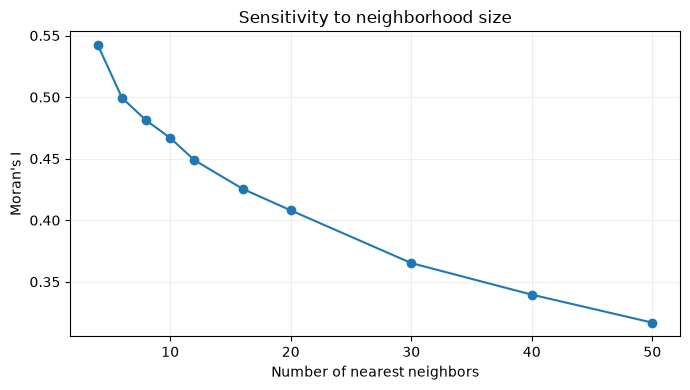

In [30]:
k_values = [k_test for k_test in [4, 6, 8, 10, 12, 16, 20, 30, 40, 50]
            if k_test < len(samples)]
results = []
for k_test in k_values:
    weights = KNN.from_dataframe(samples, k=k_test)
    weights.transform = "R"
    np.random.seed(SEED)
    statistic = Moran(samples["AGB"].to_numpy(), weights, permutations=999)
    results.append({"k": k_test, "I": statistic.I, "p_sim": statistic.p_sim,
                    "components": weights.n_components})
moran_results = pd.DataFrame(results)
display(moran_results)
ax = moran_results.plot(x="k", y="I", marker="o", legend=False, figsize=(7, 4))
ax.set(xlabel="Number of nearest neighbors", ylabel="Moran's I",
       title="Sensitivity to neighborhood size")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 4.4 Local Moran (LISA)

Using the same 8-neighbor definition as section 4.2, identify locations with high or low AGB surrounded by similar or dissimilar values. The map uses two-sided permutation pseudo-p-values and Benjamini–Hochberg correction for multiple tests. Interpret clusters as exploratory: the tests are spatially dependent, and 999 permutations limit p-value resolution.

Raw p < 0.05: 543; BH-adjusted p < 0.05: 251


,samples
cluster,
High-High,122
Low-Low,117
High-Low,9
Low-High,3
Not significant,1264


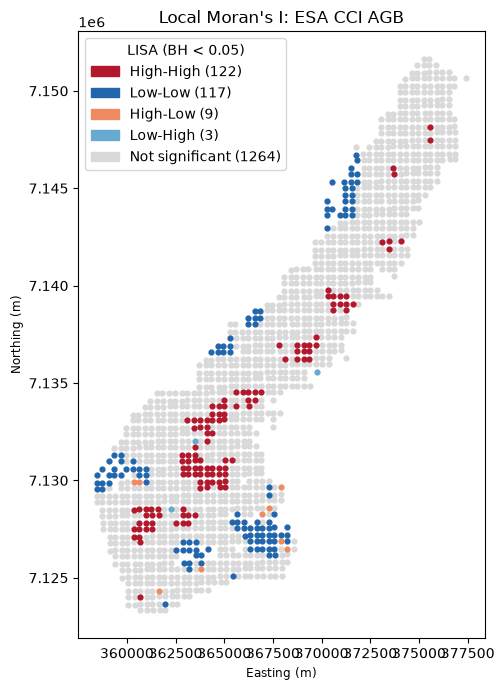

In [31]:
from matplotlib.patches import Patch
from scipy.stats import false_discovery_control

lisa_weights = KNN.from_dataframe(samples, k=8)
lisa_weights.transform = "R"
lisa = Moran_Local(
    samples["AGB"].to_numpy(), lisa_weights, permutations=999,
    seed=SEED, n_jobs=1, keep_simulations=False, alternative="two-sided",
)
lisa_p_adjusted = false_discovery_control(lisa.p_sim, method="bh")
quadrants = {1: "High-High", 2: "Low-High", 3: "Low-Low", 4: "High-Low"}
lisa_samples = samples.copy()
lisa_samples["local_moran"] = lisa.Is
lisa_samples["p_sim"] = lisa.p_sim
lisa_samples["p_adjusted"] = lisa_p_adjusted
lisa_samples["cluster"] = [
    quadrants[q] if p < 0.05 else "Not significant"
    for q, p in zip(lisa.q, lisa_p_adjusted)
]
colors = {"High-High": "#b2182b", "Low-Low": "#2166ac",
          "High-Low": "#ef8a62", "Low-High": "#67a9cf",
          "Not significant": "#d9d9d9"}
counts = lisa_samples["cluster"].value_counts().reindex(colors, fill_value=0)
print(f"Raw p < 0.05: {(lisa.p_sim < 0.05).sum()}; "
      f"BH-adjusted p < 0.05: {(lisa_p_adjusted < 0.05).sum()}")
display(counts.rename("samples").to_frame())

fig, ax = plt.subplots(figsize=(8, 7))
for category in ["Not significant", "High-High", "Low-Low", "High-Low", "Low-High"]:
    subset = lisa_samples[lisa_samples["cluster"] == category]
    if not subset.empty:
        subset.plot(ax=ax, color=colors[category], markersize=12)
ax.legend(handles=[Patch(color=colors[name], label=f"{name} ({counts[name]})")
                   for name in colors], title="LISA (BH < 0.05)")
ax.set(title="Local Moran's I: ESA CCI AGB", xlabel="Easting (m)", ylabel="Northing (m)")
plt.tight_layout()
plt.show()

## 4.5 Semivariogram and range

As in the course notebook, remove a linear spatial trend and fit a spherical semivariogram to the residuals. Also inspect the original AGB and an exponential model to assess sensitivity. The maximum lag is half the bounding-box diagonal, rather than the 30 km used for a national dataset. Pair counts and the empirical curve help assess the fit.

The fitted range is an exploratory guide, not an automatic block size or a guarantee of train–test separation. These whole-area results are descriptive: model selection and any data-driven tuning must use training data only.

Linear spatial trend R²: 0.024
Maximum lag: 17.04 km


,data,model,effective_range_km,sill,nugget,fit_rmse
0,AGB,spherical,4.720018,2396.443182,1.266920e+03,151.244694
1,Detrended AGB,spherical,4.566859,2311.080156,1.281620e+03,161.975790
2,Detrended AGB,exponential,3.711600,3593.455957,7.676973e-12,183.812789


,lag_upper_km,pairs
0,1.135997,22976
1,2.271994,62434
2,3.407990,81625
3,4.543987,92005
4,5.679984,89016
5,6.815981,83501
6,7.951977,76542
7,9.087974,67424
8,10.223971,58232
9,11.359968,53371


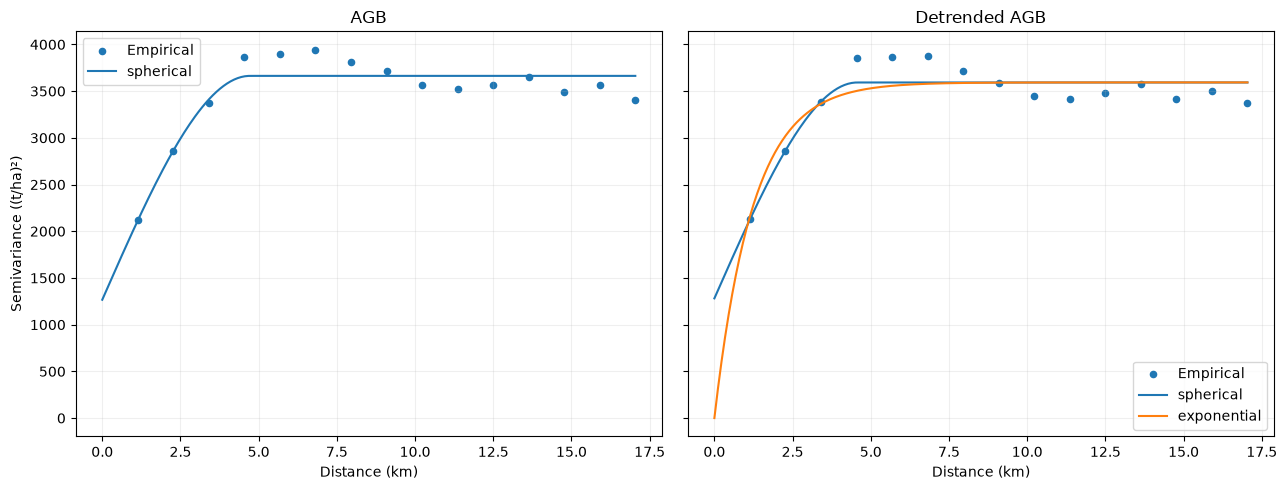

In [32]:
from sklearn.linear_model import LinearRegression

coordinates = np.column_stack((samples.geometry.x, samples.geometry.y))
agb_values = samples["AGB"].to_numpy()
trend_model = LinearRegression().fit(coordinates, agb_values)
trend_residuals = agb_values - trend_model.predict(coordinates)
max_lag_m = np.linalg.norm(np.ptp(coordinates, axis=0)) / 2
print(f"Linear spatial trend R²: {trend_model.score(coordinates, agb_values):.3f}")
print(f"Maximum lag: {max_lag_m / 1000:.2f} km")

variograms = {}
for data_name, data, model in [
    ("AGB", agb_values, "spherical"),
    ("Detrended AGB", trend_residuals, "spherical"),
    ("Detrended AGB", trend_residuals, "exponential"),
]:
    variograms[(data_name, model)] = Variogram(
        coordinates, data, model=model, n_lags=15, maxlag=max_lag_m,
        normalize=False, use_nugget=True,
    )

variogram_results = []
for (data_name, model), variogram in variograms.items():
    params = variogram.describe()
    variogram_results.append({
        "data": data_name, "model": model,
        "effective_range_km": params["effective_range"] / 1000,
        "sill": params["sill"], "nugget": params["nugget"],
        "fit_rmse": variogram.rmse,
    })
variogram_results = pd.DataFrame(variogram_results)
display(variogram_results)
if (variogram_results["effective_range_km"] >= 0.95 * max_lag_m / 1000).any():
    print("Warning: a fitted range is near the maximum lag; the sill may not be established.")

reference_variogram = variograms[("Detrended AGB", "spherical")]
display(pd.DataFrame({"lag_upper_km": reference_variogram.bins / 1000,
                      "pairs": reference_variogram.bin_count}))
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
distances = np.linspace(0, max_lag_m, 300)
for ax, data_name in zip(axes, ["AGB", "Detrended AGB"]):
    empirical = variograms[(data_name, "spherical")]
    ax.scatter(empirical.bins / 1000, empirical.experimental, label="Empirical", s=20)
    for (name, model), variogram in variograms.items():
        if name == data_name:
            ax.plot(distances / 1000, variogram.fitted_model(distances), label=model)
    ax.set(title=data_name, xlabel="Distance (km)")
    ax.grid(alpha=0.2)
    ax.legend()
axes[0].set_ylabel("Semivariance ((t/ha)²)")
plt.tight_layout()
plt.show()

# 5. Spatial split and cross-validation

Following the block allocation in `cap423-slides/05/04_Script_ML_GDS_Python_spatialCV.ipynb`, adapted to this smaller AOI. A fixed grid of 4.5 km and five folds are starting choices informed by the exploratory variogram and the available blocks, not guarantees of independence. Whole blocks are assigned to a roughly 25% test set or to training folds.

The test blocks are scattered across the AOI, so they primarily evaluate prediction in unsampled local blocks, not transfer to a distant region. Adjacent blocks can contain close samples; section 5.4 measures the actual distances. Because the earlier ESDA used all responses to inform the block size, this test is not strictly untouched by exploratory design.

## 5.1 Spatial blocks (candidate size informed by the variogram)

In [33]:
# Keep exactly the predictor columns used by the original notebook.
model_samples = samples.copy()
model_samples[predictor_columns] = (
    model_samples[predictor_columns].apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
)
complete = model_samples[["AGB"] + predictor_columns].notna().all(axis=1)
print(f"Samples removed for missing modeling values: {(~complete).sum()}")
model_samples = model_samples.loc[complete].reset_index(drop=True)
if model_samples.empty or model_samples.crs is None or model_samples.crs.is_geographic:
    raise ValueError("Nonempty samples in a projected metric CRS are required.")

BLOCK_SIZE = 4500  # metres; exploratory candidate, not an independence threshold
N_FOLDS = 5
TEST_FRACTION = 0.25
origin_x = np.floor(model_samples.geometry.x.min() / BLOCK_SIZE) * BLOCK_SIZE
origin_y = np.floor(model_samples.geometry.y.min() / BLOCK_SIZE) * BLOCK_SIZE
model_samples["block_col"] = np.floor((model_samples.geometry.x - origin_x) / BLOCK_SIZE).astype(int)
model_samples["block_row"] = np.floor((model_samples.geometry.y - origin_y) / BLOCK_SIZE).astype(int)
model_samples["block_id"] = (
    model_samples["block_col"].astype(str) + "_" + model_samples["block_row"].astype(str)
)
block_index = model_samples[["block_id", "block_col", "block_row"]].drop_duplicates().copy()
blocks_gdf = gpd.GeoDataFrame(
    block_index,
    geometry=[
        box(origin_x + col * BLOCK_SIZE, origin_y + row * BLOCK_SIZE,
            origin_x + (col + 1) * BLOCK_SIZE, origin_y + (row + 1) * BLOCK_SIZE)
        for col, row in zip(block_index["block_col"], block_index["block_row"])
    ],
    crs=model_samples.crs,
)
print(f"Modeling samples: {len(model_samples)}; occupied blocks: {len(blocks_gdf)}")

Samples removed for missing modeling values: 0
Modeling samples: 1515; occupied blocks: 19


## 5.2 Spatial training and held-out test

Randomly assign whole blocks, targeting approximately 25% of **samples** for testing, as in the course example. The exact percentage depends on block sizes. The test data are not used in feature selection.

In [34]:
block_counts = model_samples.groupby("block_id").size().rename("n").reset_index()
if len(block_counts) <= N_FOLDS:
    raise ValueError("Not enough occupied blocks for the test set and training folds.")
rng_split = np.random.RandomState(SEED)
block_counts = block_counts.iloc[rng_split.permutation(len(block_counts))].reset_index(drop=True)
max_test_blocks = len(block_counts) - N_FOLDS
target_test_count = round(TEST_FRACTION * len(model_samples))
test_cut = np.argmin(
    np.abs(block_counts["n"].cumsum().to_numpy()[:max_test_blocks] - target_test_count)
) + 1
test_blocks = set(block_counts.iloc[:test_cut]["block_id"])
train_blocks = set(block_counts["block_id"]) - test_blocks
if not test_blocks or not train_blocks or train_blocks & test_blocks:
    raise RuntimeError("Invalid spatial train/test block assignment.")
model_samples["dataset"] = np.where(
    model_samples["block_id"].isin(test_blocks), "Test", "Training"
)
print(model_samples["dataset"].value_counts())
print(f"Test proportion: {(model_samples['dataset'] == 'Test').mean():.1%}")
print(f"Training blocks: {len(train_blocks)}; test blocks: {len(test_blocks)}")

dataset
Training    1118
Test         397
Name: count, dtype: int64
Test proportion: 26.2%
Training blocks: 14; test blocks: 5


## 5.3 Spatial folds (five)

Allocate whole training blocks to folds, largest first, balancing sample counts as in the course. The held-out test blocks have no fold.

In [35]:
train_counts = (model_samples.loc[model_samples["dataset"] == "Training"]
                .groupby("block_id").size().rename("n").reset_index())
if len(train_counts) < N_FOLDS:
    raise ValueError("Not enough training blocks for spatial cross-validation.")
rng_folds = np.random.RandomState(SEED)
train_counts["tie_break"] = rng_folds.uniform(size=len(train_counts))
train_counts = train_counts.sort_values(["n", "tie_break"], ascending=[False, True])
fold_sizes = np.zeros(N_FOLDS, dtype=int)
fold_assignment = {}
for block_id, count in zip(train_counts["block_id"], train_counts["n"]):
    fold = int(rng_folds.choice(np.flatnonzero(fold_sizes == fold_sizes.min())))
    fold_assignment[block_id] = fold + 1
    fold_sizes[fold] += count
model_samples["fold"] = model_samples["block_id"].map(fold_assignment)

train_spatial = model_samples.loc[model_samples["dataset"] == "Training"].reset_index(drop=True)
test_spatial = model_samples.loc[model_samples["dataset"] == "Test"].reset_index(drop=True)
X_train = train_spatial[predictor_columns].copy()
y_train = train_spatial["AGB"].copy()
X_test = test_spatial[predictor_columns].copy()
y_test = test_spatial["AGB"].copy()
spatial_cv = []
for fold in range(1, N_FOLDS + 1):
    val_idx = np.flatnonzero(train_spatial["fold"].to_numpy() == fold)
    train_idx = np.flatnonzero(train_spatial["fold"].to_numpy() != fold)
    if len(val_idx) == 0 or len(train_idx) == 0:
        raise ValueError(f"Spatial fold {fold} is empty.")
    if set(train_spatial.iloc[train_idx]["block_id"]) & set(train_spatial.iloc[val_idx]["block_id"]):
        raise RuntimeError(f"Block overlap in spatial fold {fold}.")
    spatial_cv.append((train_idx, val_idx))
if not np.array_equal(np.sort(np.concatenate([val for _, val in spatial_cv])), np.arange(len(X_train))):
    raise RuntimeError("Spatial validation folds do not cover the training samples exactly once.")
print("Spatial CV: no blocks shared between train and validation in any fold.")

Spatial CV: no blocks shared between train and validation in any fold.


## 5.4 Diagnostics

,fold,train_samples,validation_samples,validation_blocks,min_distance_km,median_distance_km
0,1,902,216,3,0.270124,0.990076
1,2,890,228,3,0.270216,1.261126
2,3,884,234,2,0.270110,1.367434
3,4,899,219,4,0.270110,2.500450
4,5,897,221,2,0.270124,0.995003


Test to nearest training sample (km): min 0.27, median 1.26, max 2.84
Blocks alone do not enforce a minimum train–test distance.


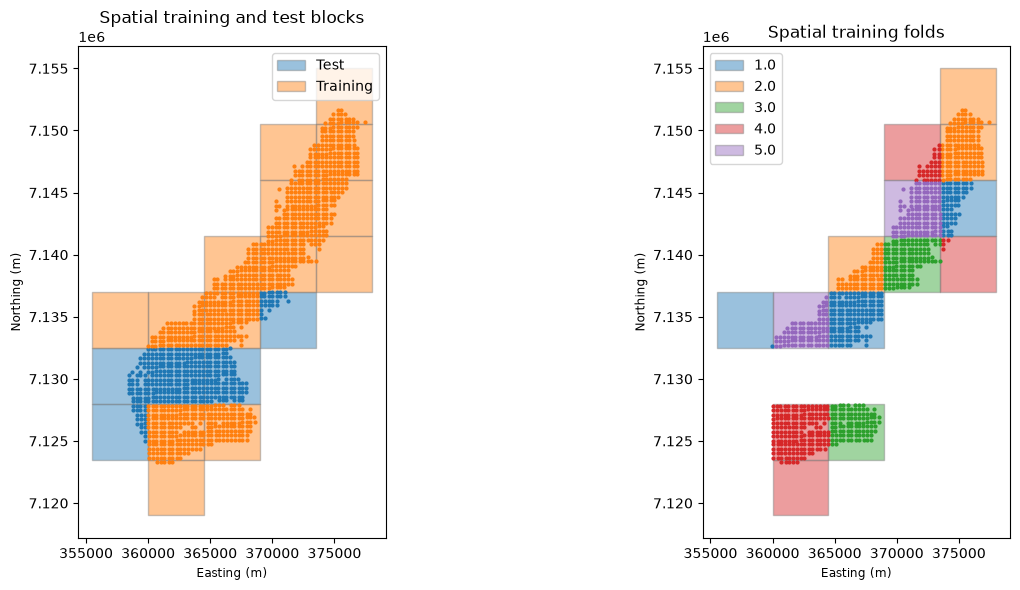

In [37]:
from scipy.spatial import cKDTree

def nearest_train_distance(reference, query):
    ref_xy = np.column_stack((reference.geometry.x, reference.geometry.y))
    query_xy = np.column_stack((query.geometry.x, query.geometry.y))
    return cKDTree(ref_xy).query(query_xy, k=1)[0] / 1000

fold_diagnostics = []
for fold, (train_idx, val_idx) in enumerate(spatial_cv, 1):
    distances = nearest_train_distance(train_spatial.iloc[train_idx], train_spatial.iloc[val_idx])
    fold_diagnostics.append({
        "fold": fold, "train_samples": len(train_idx), "validation_samples": len(val_idx),
        "validation_blocks": train_spatial.iloc[val_idx]["block_id"].nunique(),
        "min_distance_km": distances.min(), "median_distance_km": np.median(distances),
    })
display(pd.DataFrame(fold_diagnostics))
test_distances = nearest_train_distance(train_spatial, test_spatial)
print(f"Test to nearest training sample (km): min {test_distances.min():.2f}, "
      f"median {np.median(test_distances):.2f}, max {test_distances.max():.2f}")
print("Blocks alone do not enforce a minimum train–test distance.")

block_info = model_samples[["block_id", "dataset", "fold"]].drop_duplicates("block_id")
blocks_plot = blocks_gdf.merge(block_info, on="block_id", validate="one_to_one")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
blocks_plot.plot(column="dataset", categorical=True, legend=True, alpha=0.45,
                 edgecolor="gray", ax=axes[0])
model_samples.plot(column="dataset", categorical=True, markersize=4, legend=False, ax=axes[0])
axes[0].set_title("Spatial training and test blocks")
blocks_plot.loc[blocks_plot["dataset"] == "Training"].plot(
    column="fold", categorical=True, legend=True, alpha=0.45, edgecolor="gray", ax=axes[1]
)
train_spatial.plot(column="fold", categorical=True, markersize=4, legend=False, ax=axes[1])
axes[1].set_title("Spatial training folds")
for ax in axes:
    ax.set(xlabel="Easting (m)", ylabel="Northing (m)")
plt.tight_layout()
plt.show()

## 5.5 Random CV baseline

The same training samples and five folds can be used to compare random and spatial CV later. These assess different prediction settings; a random split is not automatically equivalent to the original notebook's grouping.

In [38]:
random_cv = list(KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(X_train))
print(f"Random and spatial CV prepared on the same {len(X_train)} training samples.")

Random and spatial CV prepared on the same 1118 training samples.


# 6. Spatial feature selection

Following the original RF workflow, compare MDI and permutation importance (MDA), computed on each fold's **training** data. As in the original, fit `MinMaxScaler` only on the fold's training part; tree models generally do not need scaling, but this preserves the original workflow.

For each ranking and feature count, compute validation RMSE on spatial folds. These scores choose a procedure and feature count; they are not unbiased final performance estimates after choosing the minimum. The held-out test is reserved for the subsequent model comparison. Training-set permutation importance can be optimistic, and correlated predictors can share or distort importance.

`selected_features` is fitted on all training samples for the final model. To assess the entire selection procedure with CV later, repeat the selection (including method and feature count) inside each outer training fold; using this fixed list across CV folds would leak validation information. Using the same RF-selected predictors for RF and GRF controls the inputs, but may favor RF; comparing with all predictors is a useful later sensitivity check.

## 6.1 Mean Decrease in Impurity (MDI)

Mean training-fold MDI (descriptive):


,MDI
b1,0.189491
Lcaroc,0.172822
NBR,0.086369
LAI,0.078103
NDVI,0.063560
elevation,0.044868
Sigma0_VV,0.028834
SRNIRnarrowRededge1,0.027815
Sigma0_VH,0.024204
PSRI,0.022823


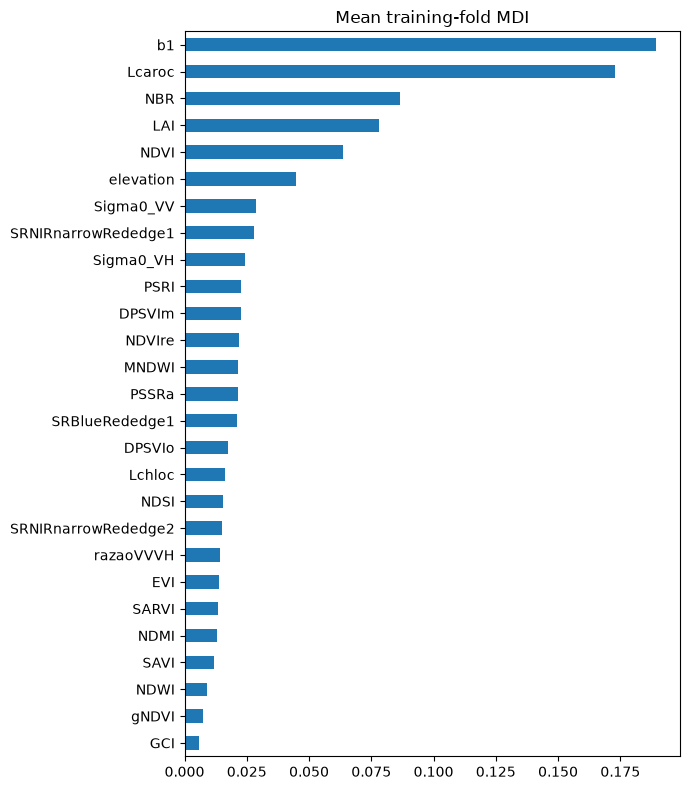

In [39]:
from sklearn.preprocessing import MinMaxScaler

# Cache each fold's training-only scaler, RF, and MDI ranking for section 6.
fold_feature_data = []
for fold, (train_idx, val_idx) in enumerate(spatial_cv, 1):
    scaler = MinMaxScaler().fit(X_train.iloc[train_idx])
    fold_X_train = pd.DataFrame(scaler.transform(X_train.iloc[train_idx]), columns=predictor_columns)
    fold_X_val = pd.DataFrame(scaler.transform(X_train.iloc[val_idx]), columns=predictor_columns)
    fold_y_train = y_train.iloc[train_idx].reset_index(drop=True)
    fold_y_val = y_train.iloc[val_idx].reset_index(drop=True)
    forest = RandomForestRegressor(random_state=SEED, n_jobs=1)
    forest.fit(fold_X_train, fold_y_train)
    mdi = pd.Series(forest.feature_importances_, index=predictor_columns)
    fold_feature_data.append({
        "fold": fold, "X_train": fold_X_train, "X_val": fold_X_val,
        "y_train": fold_y_train, "y_val": fold_y_val, "forest": forest,
        "MDI": mdi,
    })
mdi_importance = pd.concat([f["MDI"] for f in fold_feature_data], axis=1).mean(axis=1)
print("Mean training-fold MDI (descriptive):")
display(mdi_importance.sort_values(ascending=False).to_frame("MDI"))
mdi_importance.sort_values().plot.barh(figsize=(7, 8), title="Mean training-fold MDI")
plt.tight_layout()
plt.show()

## 6.2 Mean Decrease in Accuracy (MDA)

Mean training-fold permutation importance (descriptive, R² decrease):


,MDA
b1,0.454781
Lcaroc,0.080898
elevation,0.074853
NBR,0.068240
Sigma0_VV,0.055176
Sigma0_VH,0.036059
DPSVIm,0.034562
PSRI,0.031728
LAI,0.029295
MNDWI,0.028599


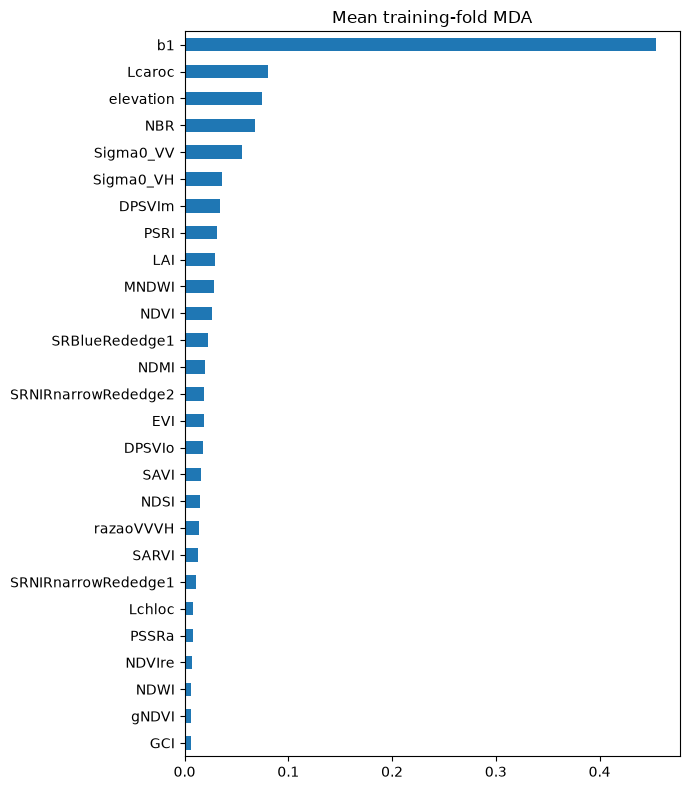

In [40]:
# Match the original notebook: permutation importance on training data with 30 repeats.
for fold_data in fold_feature_data:
    result = permutation_importance(
        fold_data["forest"], fold_data["X_train"], fold_data["y_train"],
        n_repeats=30, random_state=SEED, n_jobs=1,
    )
    fold_data["MDA"] = pd.Series(result.importances_mean, index=predictor_columns)
mda_importance = pd.concat([f["MDA"] for f in fold_feature_data], axis=1).mean(axis=1)
print("Mean training-fold permutation importance (descriptive, R² decrease):")
display(mda_importance.sort_values(ascending=False).to_frame("MDA"))
mda_importance.sort_values().plot.barh(figsize=(7, 8), title="Mean training-fold MDA")
plt.tight_layout()
plt.show()

## 6.3 RMSE vs. number of features

Feature selection evaluated for fold 1/5
Feature selection evaluated for fold 2/5
Feature selection evaluated for fold 3/5
Feature selection evaluated for fold 4/5
Feature selection evaluated for fold 5/5
Selection: MDI, 16 features; mean spatial CV RMSE = 34.70 t/ha (selection score)


,method,n_features,mean_rmse,std_rmse
42,MDI,16,34.700007,3.984581
40,MDI,14,34.713211,4.431354
39,MDI,13,34.771724,4.588530
41,MDI,15,34.786989,4.294454
36,MDI,10,34.803420,4.094005
33,MDI,7,34.812712,4.878924
37,MDI,11,34.829622,4.256923
23,MDA,24,34.850004,3.775308
44,MDI,18,34.886133,3.949907
52,MDI,26,34.905219,3.957699


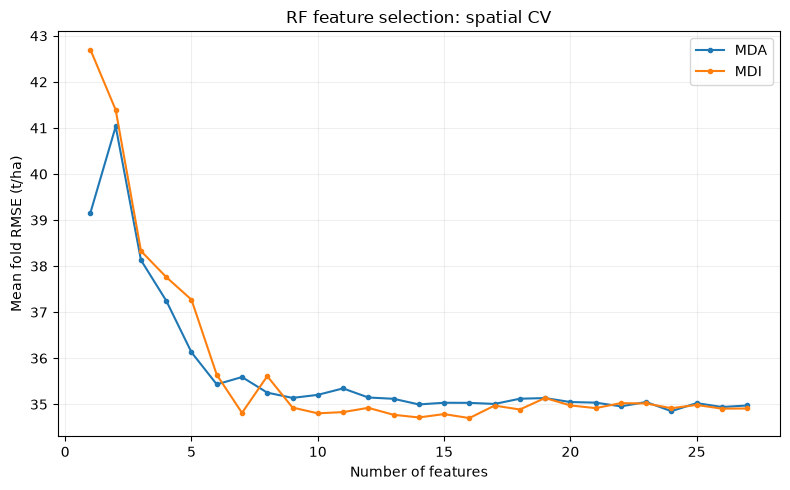

Selected features for both RF and GRF: ['b1', 'Lcaroc', 'LAI', 'NBR', 'NDVI', 'elevation', 'Sigma0_VV', 'PSSRa', 'SRNIRnarrowRededge1', 'DPSVIm', 'MNDWI', 'Sigma0_VH', 'PSRI', 'SRBlueRededge1', 'DPSVIo', 'Lchloc']


In [41]:
# Rank within each training fold before evaluating each subset in its validation fold.
feature_curve = []
for fold_data in fold_feature_data:
    for method in ["MDI", "MDA"]:
        ranking = fold_data[method].sort_values(ascending=False, kind="stable").index.tolist()
        for n_features in range(1, len(ranking) + 1):
            selected = ranking[:n_features]
            forest = RandomForestRegressor(random_state=SEED, n_jobs=1)
            forest.fit(fold_data["X_train"][selected], fold_data["y_train"])
            predicted = forest.predict(fold_data["X_val"][selected])
            rmse = np.sqrt(mean_squared_error(fold_data["y_val"], predicted))
            feature_curve.append({
                "fold": fold_data["fold"], "method": method,
                "n_features": n_features, "rmse": rmse,
            })
    print(f"Feature selection evaluated for fold {fold_data['fold']}/{N_FOLDS}")
feature_curve = pd.DataFrame(feature_curve)
feature_summary = (feature_curve.groupby(["method", "n_features"])["rmse"]
                   .agg(mean_rmse="mean", std_rmse="std").reset_index())
best = feature_summary.sort_values(["mean_rmse", "n_features", "method"]).iloc[0]
best_method, best_n_features = best["method"], int(best["n_features"])
print(f"Selection: {best_method}, {best_n_features} features; "
      f"mean spatial CV RMSE = {best['mean_rmse']:.2f} t/ha (selection score)")
display(feature_summary.sort_values("mean_rmse").head(10))

fig, ax = plt.subplots(figsize=(8, 5))
for method, group in feature_summary.groupby("method"):
    ax.plot(group["n_features"], group["mean_rmse"], marker=".", label=method)
ax.set(xlabel="Number of features", ylabel="Mean fold RMSE (t/ha)",
       title="RF feature selection: spatial CV")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Recompute the winning ranking on all training samples, never on the test set.
selection_scaler = MinMaxScaler().fit(X_train)
X_train_scaled = pd.DataFrame(selection_scaler.transform(X_train), columns=predictor_columns)
selection_forest = RandomForestRegressor(random_state=SEED, n_jobs=1).fit(X_train_scaled, y_train)
if best_method == "MDI":
    final_importance = pd.Series(selection_forest.feature_importances_, index=predictor_columns)
else:
    final_result = permutation_importance(
        selection_forest, X_train_scaled, y_train, n_repeats=30, random_state=SEED, n_jobs=1
    )
    final_importance = pd.Series(final_result.importances_mean, index=predictor_columns)
selected_features = final_importance.sort_values(ascending=False, kind="stable").index[:best_n_features].tolist()
print("Selected features for both RF and GRF:", selected_features)

# 7. Models

## 7.1 Random Forest

In [ ]:
# TODO: Bayesian search (n_estimators, max_depth, min_samples_split, min_samples_leaf) with spatial CV

## 7.2 Spatial model: Geographical Random Forest
Inspired by `cap423-slides/06/10_GRF_Classification_PyGRF_spatialCV.ipynb`, adapted to continuous AGB regression. Local models and their neighborhood choices must be fitted using training samples only.

In [ ]:
# TODO: fit and evaluate GRF with spatial CV and the held-out test

# 8. Accuracy assessment

## 8.1 Metrics: random CV vs. spatial CV vs. independent test

In [ ]:
# TODO: table (RMSE, MAE, R2) per model, built from code (no hard-coded values)

## 8.2 Observed vs. predicted and fold-wise metrics

In [ ]:
# TODO: scatter plots, per-fold metrics plot, paired comparison of models across folds

## 8.3 Residual spatial autocorrelation

In [ ]:
# TODO: Moran's I of the residuals per model, residual map

# 9. Model explanation with SHAP

In [ ]:
# TODO: explain the fitted RF and, if appropriate, the spatial model

# 10. Final map
Based on `cap423-slides/05/03_Script_ML_GDS_Python.ipynb` (prediction over rasters).

In [ ]:
# TODO: export predictor stack for the AOI, read with rasterio

In [ ]:
# TODO: predict AGB raster with the best model (refit on all training data), save GeoTIFF

In [ ]:
# TODO: difference map vs. ESA CCI and uncertainty map (std across RF trees)

## Optional extensions
- Area of Applicability / nearest-neighbor distance between samples and prediction pixels.
- GEDI L4A (`agbd`) as an alternative target.